# Car Price Prediction Using Machine Learning

## Objective

The objective of this project is to predict the price of cars using various independent variables and compare the performance of different regression algorithms.

## Algorithms Used

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. Support Vector Regressor

In [2]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Check the current working directory
import os

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR

# Import evaluation metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Import tools for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Display plots inside the notebook
%matplotlib inline

In [3]:
# Load the uploaded car price dataset
df = pd.read_csv("CarPrice.csv")

# Display the first five rows
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [4]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (205, 26)


In [5]:
# Display all column names
print(df.columns.tolist())

['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [6]:
# Display column information and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [7]:
# Display descriptive statistics for numerical columns
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [8]:
# Count missing values in each column
print(df.isnull().sum())

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


In [9]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 4. Data Preprocessing

Data preprocessing prepares the dataset for machine learning by handling unnecessary columns and converting categorical variables into numerical representations.

In [10]:
# Create a brand feature from the car name
df["brand"] = (
    df["CarName"]
    .str.strip()
    .str.split()
    .str[0]
    .str.lower()
)

# Display some extracted brands
print(df[["CarName", "brand"]].head(10))

                    CarName        brand
0        alfa-romero giulia  alfa-romero
1       alfa-romero stelvio  alfa-romero
2  alfa-romero Quadrifoglio  alfa-romero
3               audi 100 ls         audi
4                audi 100ls         audi
5                  audi fox         audi
6                audi 100ls         audi
7                 audi 5000         audi
8                 audi 4000         audi
9       audi 5000s (diesel)         audi


In [11]:
# Remove the identifier and original car name
df = df.drop(columns=["car_ID", "CarName"])

# Display the remaining columns
print(df.columns.tolist())

['symboling', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price', 'brand']


In [12]:
# Separate the independent variables
X = df.drop(columns=["price"])

# Select the target variable
y = df["price"]

# Display feature and target shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (205, 24)
Target shape: (205,)


In [13]:
# Split the data into training and testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the number of records in each set
print("Training records:", X_train_raw.shape[0])
print("Testing records:", X_test_raw.shape[0])

Training records: 164
Testing records: 41


In [14]:
# Convert categorical columns in the training data into dummy variables
X_train = pd.get_dummies(
    X_train_raw,
    drop_first=True,
    dtype=int
)

# Apply the same encoding approach to the testing data
X_test = pd.get_dummies(
    X_test_raw,
    drop_first=True,
    dtype=int
)

# Align testing columns with the training columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Display the encoded shapes
print("Encoded training shape:", X_train.shape)
print("Encoded testing shape:", X_test.shape)

# Confirm that the columns match
print("Columns match:", X_train.columns.equals(X_test.columns))

Encoded training shape: (164, 67)
Encoded testing shape: (41, 67)
Columns match: True


In [15]:
# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the learned parameters to testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


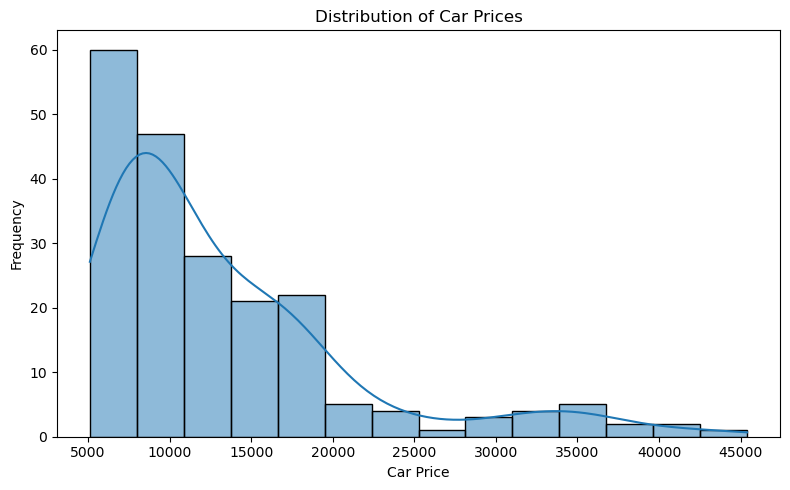

In [16]:
# Plot the distribution of car prices
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="price", kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

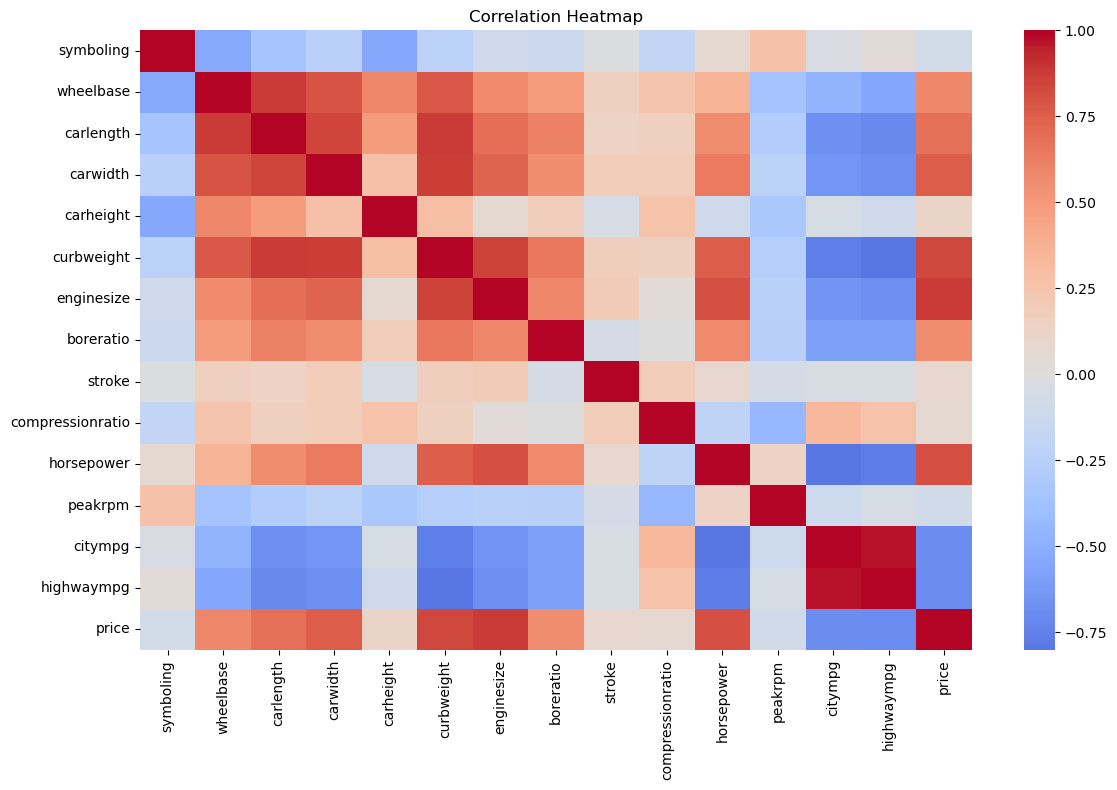

In [17]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlations between numerical variables
correlation = numeric_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

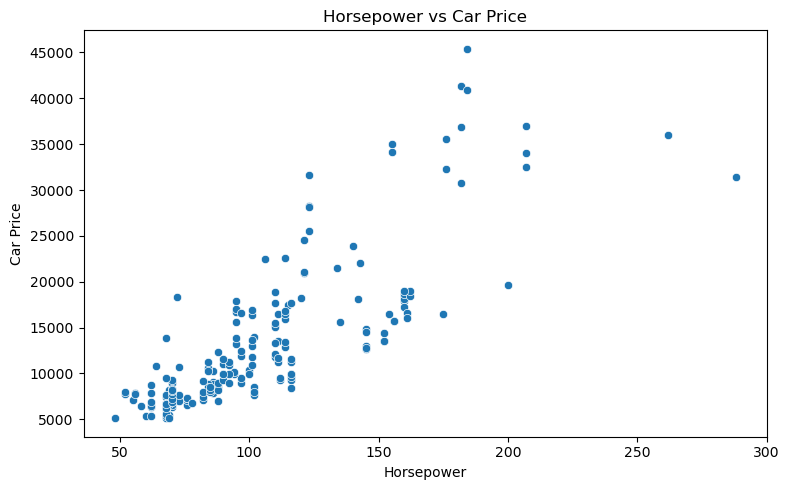

In [18]:
# Plot horsepower against car price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="horsepower",
    y="price"
)

plt.title("Horsepower vs Car Price")
plt.xlabel("Horsepower")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()

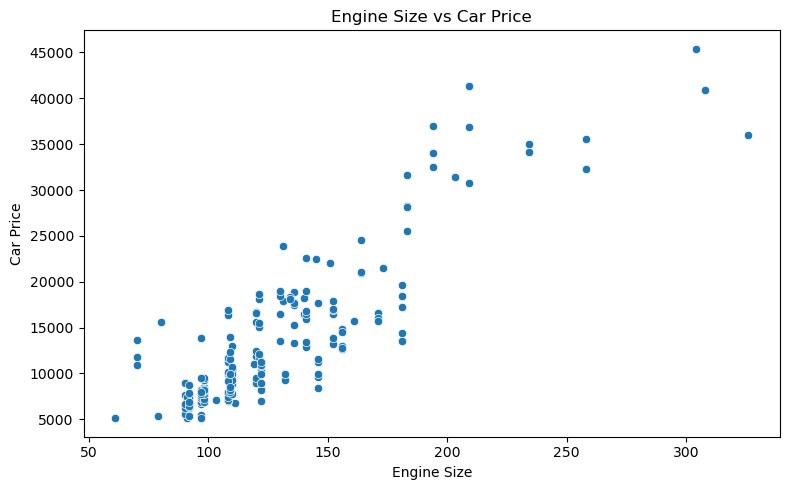

In [19]:
# Plot engine size against car price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="enginesize",
    y="price"
)

plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()

## 5. Regression Model Implementation

Five regression algorithms are implemented to predict car prices. All models use the same training and testing data for a fair comparison.

In [20]:
# Create the five regression models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "Support Vector Regressor": SVR()
}

print("All five regression models are ready.")

All five regression models are ready.


In [21]:
# Store the trained models
trained_models = {}

# Train every model using the scaled training data
for name, model in models.items():

    print("Training:", name)

    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

print("All models trained successfully.")

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting
Training: Support Vector Regressor
All models trained successfully.


## 6. Model Evaluation

The models are evaluated on the unseen test set using R-squared, Mean Squared Error, and Mean Absolute Error.

In [22]:
# Store predictions and evaluation results
predictions = {}
results = []

# Predict and evaluate every trained model
for name, model in trained_models.items():

    # Predict car prices on the test set
    y_pred = model.predict(X_test_scaled)

    # Save predictions
    predictions[name] = y_pred

    # Calculate evaluation metrics
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    # Save metrics for comparison
    results.append({
        "Model": name,
        "R2": r2,
        "MSE": mse,
        "MAE": mae
    })

# Create a comparison table
results_df = pd.DataFrame(results)

# Display models from highest to lowest R2
results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

results_df

,Model,R2,MSE,MAE
0,Random Forest,0.957990,3.316416e+06,1275.873935
1,Gradient Boosting,0.930521,5.484918e+06,1658.959851
2,Linear Regression,0.915255,6.690126e+06,1816.833683
3,Decision Tree,0.886811,8.935588e+06,2005.308951
4,Support Vector Regressor,-0.100665,8.689089e+07,5701.210068


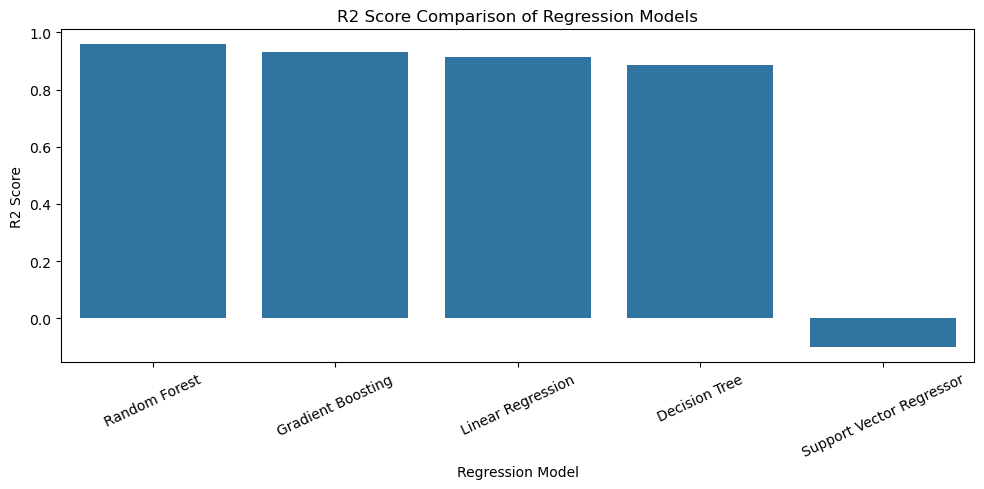

In [23]:
# Plot the R2 score of each model
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("R2 Score Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [24]:
# Identify the model with the highest test R2 score
best_model_name = results_df.loc[
    results_df["R2"].idxmax(),
    "Model"
]

print("Best baseline model:", best_model_name)

Best baseline model: Random Forest


## 7. Feature Importance Analysis

Random Forest feature importance is used to rank the input variables according to their contribution to the model's predictive decisions.

In [25]:
# Get the trained Random Forest model
rf_model = trained_models["Random Forest"]

# Extract feature importance values
importance_values = rf_model.feature_importances_

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_values
})

# Sort features from most to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the top 15 features
importance_df.head(15)

,Feature,Importance
0,enginesize,0.545302
1,curbweight,0.296310
2,highwaympg,0.046020
3,horsepower,0.034498
4,carwidth,0.012587
5,carlength,0.007647
6,brand_bmw,0.007559
7,wheelbase,0.006688
8,citympg,0.006081
9,peakrpm,0.005386


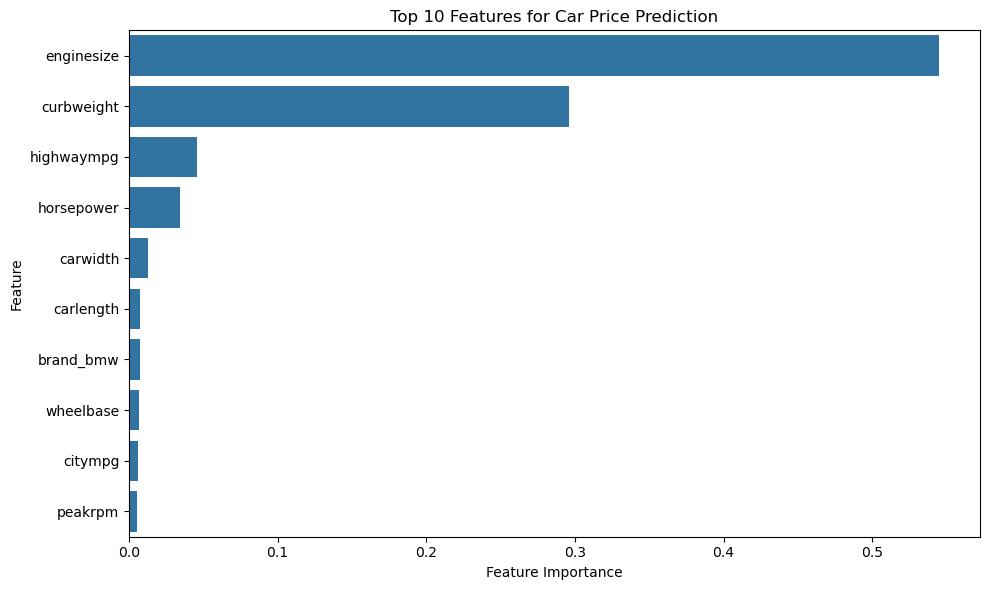

In [26]:
# Select the top 10 features
top_features = importance_df.head(10)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Car Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

The feature importance analysis identifies the variables that contribute most to the Random Forest model's predictions. The highest-ranked features are considered particularly useful for predicting car prices. These rankings describe model importance and do not establish causal relationships.

## 8. Hyperparameter Tuning

GridSearchCV with 5-fold cross-validation is used to tune the Random Forest Regressor. The tuned model is then evaluated on the same held-out test set.

In [27]:
# Create a Random Forest model
rf_for_tuning = RandomForestRegressor(
    random_state=42
)

# Define the hyperparameter search space
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_for_tuning,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Search for the best hyperparameter combination
grid_search.fit(X_train_scaled, y_train)

print("Hyperparameter tuning completed.")

Hyperparameter tuning completed.


In [28]:
# Obtain the best tuned model
best_tuned_model = grid_search.best_estimator_

# Predict prices on the held-out test set
tuned_predictions = best_tuned_model.predict(
    X_test_scaled
)

# Calculate test metrics after tuning
tuned_r2 = r2_score(y_test, tuned_predictions)

tuned_mse = mean_squared_error(
    y_test,
    tuned_predictions
)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("R2:", tuned_r2)
print("MSE:", tuned_mse)
print("MAE:", tuned_mae)

Tuned Random Forest Performance
--------------------------------
R2: 0.9585823492981834
MSE: 3269675.8817905793
MAE: 1258.9250731707316


In [29]:
# Get the baseline Random Forest results
baseline_rf = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0]

# Create a before-and-after comparison
tuning_comparison = pd.DataFrame({
    "Metric": ["R2", "MSE", "MAE"],

    "Before Tuning": [
        baseline_rf["R2"],
        baseline_rf["MSE"],
        baseline_rf["MAE"]
    ],

    "After Tuning": [
        tuned_r2,
        tuned_mse,
        tuned_mae
    ]
})

# Display the comparison
tuning_comparison

,Metric,Before Tuning,After Tuning
0,R2,9.579903e-01,9.585823e-01
1,MSE,3.316416e+06,3.269676e+06
2,MAE,1.275874e+03,1.258925e+03


In [30]:
# Display the best baseline model
print("Best baseline model:", best_model_name)

# Display the original comparison table
print("\nBaseline Model Comparison:")
display(results_df)

# Display the tuned Random Forest results
print("\nTuned Random Forest:")
print(f"R2:  {tuned_r2:.4f}")
print(f"MSE: {tuned_mse:.2f}")
print(f"MAE: {tuned_mae:.2f}")

# Compare the Random Forest before and after tuning
print("\nTuning Comparison:")
display(tuning_comparison)

Best baseline model: Random Forest

Baseline Model Comparison:


,Model,R2,MSE,MAE
0,Random Forest,0.957990,3.316416e+06,1275.873935
1,Gradient Boosting,0.930521,5.484918e+06,1658.959851
2,Linear Regression,0.915255,6.690126e+06,1816.833683
3,Decision Tree,0.886811,8.935588e+06,2005.308951
4,Support Vector Regressor,-0.100665,8.689089e+07,5701.210068



Tuned Random Forest:
R2:  0.9586
MSE: 3269675.88
MAE: 1258.93

Tuning Comparison:


,Metric,Before Tuning,After Tuning
0,R2,9.579903e-01,9.585823e-01
1,MSE,3.316416e+06,3.269676e+06
2,MAE,1.275874e+03,1.258925e+03


## 9. Conclusion

In this project, machine learning regression algorithms were used to predict automobile prices based on car specifications.

The dataset was inspected and preprocessed, categorical variables were encoded, and the data was divided into training and testing sets. Exploratory Data Analysis was performed to understand the distribution of car prices and relationships between selected car characteristics and price.

Five regression algorithms were implemented: Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, and Support Vector Regressor.

The models were evaluated using R-squared, Mean Squared Error, and Mean Absolute Error. The best-performing baseline model was **[insert model name]**, based on the test-set evaluation.

Feature importance analysis using Random Forest identified **[insert top features from your results]** as important features for predicting car prices.

Random Forest hyperparameters were tuned using GridSearchCV with 5-fold cross-validation. After tuning, the model achieved a test R² of **[value]**, MSE of **[value]**, and MAE of **[value]**. The before-and-after comparison was used to assess the impact of tuning.

Overall, this project demonstrates how regression techniques can be used to estimate car prices and investigate the importance of different automobile characteristics.